<a href="https://colab.research.google.com/github/komazawa-deep-learning/komazawa-deep-learning.github.io/blob/master/2026notebooks/2026_1016EncDec_w_attention_v5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 加算型注意 と 内積型注意 の実習

- オリジナル [Sequence-to-sequence in Pytorch](https://github.com/b-etienne/Seq2seq-PyTorch)

<center>
<img src="https://komazawa-deep-learning.github.io/assets/2015Bahdanau_attention.jpg" width="33%">
<img src="https://komazawa-deep-learning.github.io/assets/2015Loung_fig3.svg" width="33%"><br/>
</center>

## 原著論文

* [加算型注意 Bahdanau 2014 Neural Machine Translation by Jointly Learning to Align and Translate](https://arxiv.org/abs/1409.0473)
* [内積型注意 Loung 2015 Effective Approaches to Attention-based Neural Machine Translation](https://arxiv.org/abs/1508.04025)
* [Chan 2015 Listen, Attend and Spell](https://arxiv.org/abs/1508.01211)


# Seq2seq モデル

下図では，翻訳モデルで，ソース言語であるドイツ語から，ターゲット言語である英語への翻訳例である。
赤色の単語を符号化器に入力し， 英語の単語を順次出力する(青の矢印)。
すべての翻訳が青の h3 すなわち符号化器の最終時刻での中間層状態に依存していることに注意してください。

<center>
<img src="https://miro.medium.com/max/1000/1*zsOlGqCVTsEiWm--1n6Bng.png" width="49%"><br/>
ソース: http://cs224d.stanford.edu/lectures/CS224d-Lecture8.pdf
</center>

* まともに翻訳課題を例にとると，訓練に時間を要するので，今回は，おもちゃ問題で実行を確認します。
* 具体的には，系列反転課題(逆唱)を取り上げます。入力をそのまま出力する復唱課題にも切り替えられます(下の「実習の設定」)。
* 数字の順唱課題，逆唱課題は WAIS 知能検査などにも取り上げられている短期記憶を測定する手法でもあります。
* この課題を元に，注意の役割を考えるのが，今回の課題となります。
* 具体的な課題は以下のとおりです

0〜9 の 10 個の数字から，**同じ数字を重複させずに**ランダムに選んで，4〜9 桁の系列を作成します(1 つのデータセットに，4〜9 桁の系列が同数ずつ混在します)。
標的の末尾には終了記号 EOS を付けます。評価では，復号化器が **EOS を出力した時点で出力を終える**ものとし，
EOS を出さなかった場合や，早く出しすぎた場合は誤りとして数えます(正解の長さを教えません)。
このとき，符号化器に入力する文字列を，復号化器は反転することを学習するものとします(`reversed=True`。
`reversed=False` なら，反転せずそのまま出力する復唱課題になります)。
<!--

Sequence-to-sequence neural network with attention.
You can play with a toy dataset to test different configurations.
The toy dataset consists of batched (input, target) pairs, where the target is the reversed input.

### Hyper-parameters

You can tune the following parameters:

* decoder type (with or without Attention)
* encoder type (with or without downsampling, with or without preprocessing layers)
* the encoder's hidden dimension
* the number of recurrent layers in the encoder
* the encoder dropout
* the bidirectionality of the encoder
* the decoder's hidden dimension
* the number of recurrent layers in the decoder
* the decoder dropout
* the bidirectionality of the decoder
* batch size
* the type of attention used

 -->

# 実習の設定

**以下を変更して，以降のセルを実行**

| 項目 | 指定 | 内容 |
|---|---|---|
| `model` | `'GRU'` / `'LSTM'` / `'SRN'` | 再帰層の種類。符号化器と復号化器で同じ種類を使う |
| `num_layers` | 整数(既定 2) | 再帰層の数(符号化器・復号化器とも同じ) |
| `bidirectional` | `True` / `False` | **符号化器のみ**双方向にする。復号化器は 1 時刻ずつ自分の出力を使って生成する(自己回帰)ため，双方向にできない |
| `reversed` | `True` / `False` | `True`: 逆唱課題(入力を逆順に出力)。`False`: 復唱課題(入力をそのまま出力) |
| `batch_size` | 整数(既定 32) | ミニバッチの大きさ。1 エポックの更新回数は 訓練件数 ÷ batch_size なので，小さくするとエポック数が同じでも更新回数が増える |
| `grad_clip` | 数値(既定 1.0)/ `None` | 勾配全体の L2 ノルムがこの値を超えたら，この値になるよう縮小する(クリッピング)。`None` でクリップしない |
| (固定) | 数字 0〜9，重複なし，4〜9 桁 | 課題の定数。桁数ごとに訓練 512 件・評価 96 件。変えるときは `ToyDataset.MIN_LEN` / `MAX_LEN`(最大 10) / `N_TRAIN_PER_LEN` / `N_EVAL_PER_LEN` を書き換える |
| `DEVICE_NAME` | `'auto'` / `'cpu'` / `'cuda'` / `'mps'` | 計算デバイス。`'auto'` は cuda → mps → cpu の順に使えるものを選ぶ |

注意: このモデルは小さい (隠れ層 64) ので，GPU や MPS を使っても **CPU より遅くなる場合もある**。


In [ ]:
import warnings
import torch

# ==== 実習の設定 ====
OPTIONS = {
    'model': 'GRU',          # 'GRU' | 'LSTM' | 'SRN'   (符号化器と復号化器で同じ種類)
    'num_layers': 2,         # 再帰層の数 (符号化器・復号化器とも)
    'bidirectional': False,  # True: 符号化器のみ双方向。復号化器は自己回帰で生成するため双方向にできない
    'reversed': True,        # True: 逆唱課題   False: 復唱課題
    'batch_size': 32,        # ミニバッチの大きさ
    'grad_clip': 1.0,        # 勾配の L2 ノルムの上限。None ならクリップしない
}
DEVICE_NAME = 'auto'         # 'auto' | 'cpu' | 'cuda' | 'mps'


def get_device(name='auto'):
    """計算デバイスを 1 つ決める。以降のセルは、ここで決めた DEVICE だけを使う。"""
    if name == 'auto':
        if torch.cuda.is_available():
            return torch.device('cuda')
        if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
            return torch.device('mps')
        return torch.device('cpu')
    device = torch.device(name)
    if device.type == 'cuda' and not torch.cuda.is_available():
        raise RuntimeError("cuda が使えません。DEVICE_NAME を 'auto' か 'cpu' にしてください。")
    if device.type == 'mps' and not (hasattr(torch.backends, 'mps') and torch.backends.mps.is_available()):
        raise RuntimeError("mps が使えません。DEVICE_NAME を 'auto' か 'cpu' にしてください。")
    return device


DEVICE = get_device(DEVICE_NAME)

# ---- MPS についての注意 ----
# 2023 年の PyTorch 開発版で、MPS 上の双方向 LSTM (bidirectional=True) の出力が CPU と食い違うという
# 報告がある (https://discuss.pytorch.org/t/bilstm-incorrect-on-mps/172358 )。
# 現行の PyTorch で直っているかも未確認。
# model='LSTM' かつ bidirectional=True を device='mps' で使う場合は、必ず後ろの
# 「デバイス間の一致確認」セルで CPU との一致を確かめること。
# (MPS 未対応の演算で NotImplementedError が出たときは、環境変数 PYTORCH_ENABLE_MPS_FALLBACK=1 で
#  その演算だけ CPU に回せるが、速度は落ちる。)
print(f'device = {DEVICE}  /  設定 = {OPTIONS}')


# データセットの作成

PyTorch で用いるデータセット `torch.utils.data.Dataset` を自作する場合，最低限 3 つの関数をクラス内で定義します。
1. `__init__()` 初期のための関数
2. `__len__()` データセットのサイズを返す関数
3. `__getitem__()` 数値を引数にとり，その数値に該当するデータを取り出して返す関数

In [2]:
%matplotlib inline
import numpy as np
import os
import editdistance
import random
import matplotlib.pyplot as plt
import tqdm

import torch
from torch.utils import data

class ToyDataset(data.Dataset):
    """数唱課題(逆唱・復唱)のおもちゃデータ。https://talbaumel.github.io/blog/attention/ を元にした。

    - 系列: 数字 0〜9 から重複なしで選んだ MIN_LEN〜MAX_LEN 桁(両端を含む)。
      知能検査(WAIS など)の数唱課題に合わせ、同じ数字は 1 つの系列に 1 回しか現れない。
    - 桁数ごとに、訓練データは N_TRAIN_PER_LEN 件、評価データは N_EVAL_PER_LEN 件を別々に作る(各桁数が同数)。
      同じ桁数の中で系列は重複しない(訓練データの中でも、評価データの中でも)。
    - 評価データは全系列の空間から桁数ごとに一様に選び、訓練データは評価データを除いて選ぶ(exclude に評価データの
      文字列を渡す)。これで、評価データに訓練データと同じ系列は含まれない。
    - 標的: reverse=True なら入力の逆順(逆唱)、False なら入力と同じ順(復唱)。末尾に EOS(=2) を付ける。
    - 語彙: 0=PAD, 1=SOS, 2=EOS, 3〜12 = 数字 '0'〜'9'(クラス数 13)。
    - seed: 乱数シード。同じシードなら同じデータ(None なら毎回異なる)。
    - 注意: 全系列数は桁数で大きく違う(4 桁: 5,040 通り、9 桁: 362,880 通り)。訓練データが占める割合は
      4 桁で約 10%、9 桁で約 0.14% なので、短い桁数ほど訓練データの暗記が効きやすい。
    """

    N_TRAIN_PER_LEN = 512   # 桁数ごとの訓練データの件数
    N_EVAL_PER_LEN = 96     # 桁数ごとの評価データの件数
    MIN_LEN = 4             # 最小桁数(含む)
    MAX_LEN = 9             # 最大桁数(含む)。重複なしなので 10 以下

    def __init__(self, min_length=None, max_length=None, type='train', seed=None, exclude=None, reverse=True):
        self.SOS = "<s>"                       # 系列の始まりを表す特殊文字
        self.EOS = "</s>"                      # 系列の終わりを表す特殊文字
        self.characters = list("0123456789")   # 課題に使用する数字
        self.int2char = list(self.characters)
        self.char2int = {c: i+3 for i, c in enumerate(self.characters)}   # 数字 -> id (0=PAD, 1=SOS, 2=EOS の次から)

        self.VOCAB_SIZE = len(self.characters)  # 10 (入力の one-hot の次元)
        self.min_length = self.MIN_LEN if min_length is None else min_length
        self.max_length = self.MAX_LEN if max_length is None else max_length
        assert 1 <= self.min_length <= self.max_length <= len(self.characters), '重複なしなので最大 10 桁まで'
        self.reverse = reverse
        self.rng = random.Random(seed)         # グローバルな乱数状態に影響されない、このデータセット専用の乱数生成器

        n_per_len = self.N_TRAIN_PER_LEN if type == 'train' else self.N_EVAL_PER_LEN
        exclude = set(exclude) if exclude is not None else set()
        self.strings = []                      # 入力の数字列そのもの(重複確認や図の表示に使う)
        for length in range(self.min_length, self.max_length + 1):
            chosen, tries = set(), 0
            while len(chosen) < n_per_len:     # 桁数ごとに、重複なし・除外対象を避けて n_per_len 件を選ぶ
                tries += 1
                assert tries < 1000 * n_per_len, f'{length} 桁の系列が足りない(除外が多すぎる)'
                string = self._sample_string(length)
                if string in exclude or string in chosen:
                    continue
                chosen.add(string)
                self.strings.append(string)
        self.rng.shuffle(self.strings)         # 桁数の順に並んだままにしない
        self.set = [self._encode(string) for string in self.strings]

    def __len__(self):
        return len(self.set)

    def __getitem__(self, item):
        return self.set[item]

    def _sample_string(self, length=None):
        # 桁数(指定がなければ MIN_LEN〜MAX_LEN から一様に選ぶ)だけ、重複なしで数字を選ぶ
        if length is None:
            length = self.rng.randint(self.min_length, self.max_length)
        return ''.join(self.rng.sample(self.characters, length))

    def _encode(self, random_string):
        random_length = len(random_string)
        a = np.array([self.char2int.get(x) for x in random_string])                      # 数字列を id に変換
        target = random_string[::-1] if self.reverse else random_string                # 逆唱: 逆向き / 復唱: そのまま
        b = np.array([self.char2int.get(x) for x in target] + [2])                      # 標的(末尾の 2 は EOS)

        # 入力はワンホット表現: (桁数, 10)
        x = np.zeros((random_length, self.VOCAB_SIZE))
        x[np.arange(random_length), a-3] = 1

        return x, b

    def _sample(self):
        # 一つランダムサンプリングして (入力のone-hot, 標的の id 列) を返す
        return self._encode(self._sample_string())


In [3]:
dataset = ToyDataset()   # 数字 0〜9、重複なし、4〜9 桁(桁数ごとに 512 件)
print(f'データセットのサイズ: {dataset.__len__()}')
print(f'入力の数字列(先頭 5 件): {dataset.strings[:5]}')
print(f'データセットから，試しに一つデータを取り出してみる: \n{dataset.__getitem__(5)}')
print(f'データセットから一つランダムサンプリングしてみる: \n{dataset._sample()}')
from collections import Counter
print('桁数ごとの件数:', dict(sorted(Counter(len(s) for s in dataset.strings).items())))
assert all(len(set(s)) == len(s) for s in dataset.strings), '重複する数字を含む系列がある'
assert len(set(dataset.strings)) == len(dataset.strings), '同じ系列が複数回現れている'


データセットのサイズ: 3072
入力の数字列(先頭 5 件): ['7960482', '149375860', '39126478', '430571', '64503829']
データセットから，試しに一つデータを取り出してみる: 
(array([[0., 0., 0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0.],
       [0., 0., 0., 1., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]]), array([12,  3,  6, 10,  7,  9,  5, 11,  2]))
データセットから一つランダムサンプリングしてみる: 
(array([[0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0.],
       [0., 0., 0., 

* 以下の 3 つのセルは下請け作業用ですので，単純に実行してください。
* 定義だけなので，時間はかかりません

In [4]:
# utils/misc.py
EOS_TOKEN = '</s>'

def check_size(tensor, *args):
    size = [a for a in args]
    assert tensor.size() == torch.Size(size), tensor.size()

In [5]:
# utils/data_generator.py
from torch.utils import data
from itertools import zip_longest

def pad_tensor(vec, pad, value=0, dim=0):
    """
    args:
        vec - tensor to pad
        pad - the size to pad to
        dim - dimension to pad

    return:
        a new tensor padded to 'pad' in dimension 'dim'
    """
    pad_size = pad - vec.shape[0]

    if len(vec.shape) == 2:
        zeros = torch.ones((pad_size, vec.shape[-1])) * value
    elif len(vec.shape) == 1:
        zeros = torch.ones((pad_size,)) * value
    else:
        raise NotImplementedError
    return torch.cat([torch.Tensor(vec), zeros], dim=dim)


def pad_collate(batch, values=(0, 0), dim=0):
    """
    args:
        batch - list of (tensor, label)

    reutrn:
        xs - a tensor of all examples in 'batch' after padding
        ys - a LongTensor of all labels in batch
        ws - a tensor of sequence lengths
    """
    sequence_lengths = torch.Tensor([int(x[0].shape[dim]) for x in batch])
    sequence_lengths, xids = sequence_lengths.sort(descending=True)
    target_lengths = torch.Tensor([int(x[1].shape[dim]) for x in batch])
    target_lengths = target_lengths[xids]       # 標的も入力と同じ並べ替え(別々に sort すると同順位の対応が崩れうる)
    # find longest sequence
    src_max_len = max(map(lambda x: x[0].shape[dim], batch))
    tgt_max_len = max(map(lambda x: x[1].shape[dim], batch))
    # pad according to max_len
    batch = [(pad_tensor(x, pad=src_max_len, dim=dim), pad_tensor(y, pad=tgt_max_len, dim=dim)) for (x, y) in batch]

    # stack all
    xs = torch.stack([x[0] for x in batch], dim=0)
    ys = torch.stack([x[1] for x in batch]).int()
    xs = xs[xids]
    ys = ys[xids]
    return xs, ys, sequence_lengths.int(), target_lengths.int()


In [6]:
import torch
import torch.nn as nn


def make_rnn(model, input_size, hidden_size, num_layers=1, dropout=0., bidirectional=False):
    """再帰層を作る。model は 'GRU' / 'LSTM' / 'SRN'(tanh の単純再帰型)。"""
    kw = dict(num_layers=num_layers,
              dropout=dropout if num_layers > 1 else 0.,   # 層間 dropout は 2 層以上でのみ意味を持つ
              bidirectional=bidirectional,
              batch_first=True)
    if model == 'GRU':
        return nn.GRU(input_size, hidden_size, **kw)
    if model == 'LSTM':
        return nn.LSTM(input_size, hidden_size, **kw)
    if model == 'SRN':
        return nn.RNN(input_size, hidden_size, nonlinearity='tanh', **kw)
    raise ValueError(f"model は 'GRU' / 'LSTM' / 'SRN' のいずれか: {model!r}")


def top_hidden(state):
    """再帰層の状態から、最上層の隠れ状態 (B, H) を取り出す。LSTM の状態は (h, c) のタプル。
    注意のクエリには、この最上層の隠れ状態を使う。"""
    h = state[0] if isinstance(state, tuple) else state
    return h[-1]


def merge_directions(state, num_layers):
    """双方向符号化器の状態 (num_layers*2, B, H) を、復号化器の初期状態 (num_layers, B, H) にする。
    順方向と逆方向の和を取る(符号化器の出力を両方向の和にしているのと同じ方式)。"""
    def _merge(h):
        _, B, H = h.shape
        return h.view(num_layers, 2, B, H).sum(1)
    return tuple(_merge(h) for h in state) if isinstance(state, tuple) else _merge(state)


def mask_3d(inputs, seq_len, mask_value=0.):
    """系列長 seq_len より後ろ(パディング部分)を mask_value で埋める。inputs は (B, T) または (B, T, V)。
    (元のコードは Python のループで 1 行ずつ代入していた。GPU 上でも遅くならないようベクトル化した。)"""
    seq_len = torch.as_tensor(seq_len, device=inputs.device)
    assert inputs.size(0) == len(seq_len)
    assert inputs.dim() in (2, 3), f"The size of inputs must be 2 or 3, received {inputs.size()}"
    pad = torch.arange(inputs.size(1), device=inputs.device).unsqueeze(0) >= seq_len.unsqueeze(1)   # (B, T)
    if inputs.dim() == 3:
        pad = pad.unsqueeze(-1)
    return inputs.masked_fill(pad, mask_value)


def skip_add_pyramid(x, seq_len, skip_add="add"):
    if len(x.size()) == 2:
        x = x.unsqueeze(0)
    x_len = x.size()[1] // 2
    even = x[:, torch.arange(0, x_len*2-1, 2).long(), :]
    odd = x[:, torch.arange(1, x_len*2, 2).long(), :]
    if skip_add == "add":
        return (even+odd) / 2, ((seq_len) / 2).int()
    else:
        return even, (seq_len / 2).int()


# 符号化器の定義

* 符号化器は seq2seq モデルで，与えられた系列を「聞いて覚える」部分です。
* 以下で定義するリカレントニューラルネットワークです。
* 実習としては，SRN, GRU, LSTM から選ぶことができます(`OPTIONS['model']`)。層数(`num_layers`)と，双方向にするか(`bidirectional`)も選べます。
* 双方向にした場合，符号化器の出力は順方向と逆方向の和にします(隠れ層の大きさは変わらない)。
* LSTM の状態は (h, c) の 2 つ組です。多層の場合，符号化器の各層の状態を，復号化器の対応する層の初期状態として渡します。
* その前に密な層を加えることもできます(`encoder_dnn_layers`)。

符号化器にデータを入力する前に `pack_padded_sequence` と `pad_packed_sequence` ヘルパーを使っています。
データのバッチを使用しているので， バッチ内の各項目 (系列) は異なる長さを持ちますが，このバッチ内の全系列を，最長の系列の長さまで 0 で埋めることをしています。


In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class EncoderRNN(nn.Module):
    def __init__(self, config):
        super(EncoderRNN, self).__init__()
        self.input_size = config["n_channels"]
        self.hidden_size = config["encoder_hidden"]
        self.layers = config.get("encoder_layers", 1)
        self.dnn_layers = config.get("encoder_dnn_layers", 0)
        self.dropout = config.get("encoder_dropout", 0.)
        self.bi = config.get("bidirectional_encoder", False)
        self.model = config.get("model", "GRU")                 # 'GRU' / 'LSTM' / 'SRN'
        if self.dnn_layers > 0:
            for i in range(self.dnn_layers):
                self.add_module('dnn_' + str(i), nn.Linear(
                    in_features=self.input_size if i == 0 else self.hidden_size,
                    out_features=self.hidden_size
                ))
        rnn_input_dim = self.input_size if self.dnn_layers == 0 else self.hidden_size
        self.rnn = make_rnn(self.model, rnn_input_dim, self.hidden_size, self.layers,
                            dropout=self.dropout, bidirectional=self.bi)

    def run_dnn(self, x):
        for i in range(self.dnn_layers):
            x = F.relu(getattr(self, 'dnn_'+str(i))(x))
        return x

    def forward(self, inputs, hidden, input_lengths):
        """
        returns:
            output: (B, T, H)  各時刻の出力。双方向の場合は順方向と逆方向の和
            state : 復号化器の初期状態 (layers, B, H)。LSTM の場合は (h, c) のタプル
        """
        if self.dnn_layers > 0:
            inputs = self.run_dnn(inputs)
        # pack_padded_sequence は系列長が CPU 上にあることを要求する
        x = pack_padded_sequence(inputs, input_lengths.cpu(), batch_first=True)
        output, state = self.rnn(x, hidden)
        output, _ = pad_packed_sequence(output, batch_first=True, padding_value=0.)

        if self.bi:
            output = output[:, :, :self.hidden_size] + output[:, :, self.hidden_size:]
            state = merge_directions(state, self.layers)
        return output, state

    def init_hidden(self, batch_size):
        device = next(self.parameters()).device
        h0 = torch.zeros(self.layers * (2 if self.bi else 1), batch_size, self.hidden_size, device=device)
        return (h0, h0.clone()) if self.model == 'LSTM' else h0


# 復号化器の定義

* 復号化器は， 予測値を出力し，それをもとに損失値を計算します。
* 符号化器からの入力を受け取って，出力に変換します。
* このとき，以下のような 3 種類の復号化器を定義しています。
    1. バニラ復号化器
    2. Bahdanau 型注意付き復号化器
    3. Luong 型注意付き復号化器
    
* 注意つき復号化器は， 復号化器の出力を入力とし， どの部分に注目して予測を出力するかを決定します
* 注意なしのバニラモデルでは， 符号化器の最終時刻の隠れ層状態だけ使用して復号化を試みます。

* 復号化器に対する入力は，以下のものがあります
    1. 一時刻前の出力， (標的系列の次の文字，または前に出力された文字)。復号化器は 1 時刻ずつ自分の出力を使って生成する(自己回帰)ので，**双方向にはできません**(符号化器のみ双方向を選べます)
    2. 隠れ層 (中間層) の状態
    3. 注意を使っているかどうかに応じたその他の引数


## リカレントネットワーク復号化器

直下のセルでは以下の 3 つのクラスを定義しています

1. Seq2seq モデルのプロトタイプである リカレントニューラルネットワークによる復号化器のプロトタイプ
2. 加算型注意付き復号化器
3. 内積型注意付き復号化器

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Decoder(nn.Module):
    """
    復号化器のプロトタイプ
    forward() 関数は，それぞれの実装ごとに定義するので，空の実装になっています
    """
    def __init__(self, config):
        super(Decoder, self).__init__()
        if config.get("bidirectional_decoder", False):
            raise ValueError("復号化器は自己回帰で 1 時刻ずつ生成するため、双方向にはできません。"
                             "双方向にできるのは符号化器だけです (bidirectional_encoder)。")
        self.batch_size = config["batch_size"]
        self.hidden_size = config["decoder_hidden"]
        embedding_dim = config.get("embedding_dim", None)
        self.embedding_dim = embedding_dim if embedding_dim is not None else self.hidden_size
        self.embedding = nn.Embedding(config.get("n_classes", 32), self.embedding_dim, padding_idx=0)
        self.model = config.get("model", "GRU")                 # 符号化器と同じ種類 'GRU' / 'LSTM' / 'SRN'
        self.rnn = make_rnn(
            self.model,
            input_size=self.embedding_dim+self.hidden_size if config['decoder'].lower() == 'bahdanau' else self.embedding_dim,
            hidden_size=self.hidden_size,
            num_layers=config.get("decoder_layers", 1),
            dropout=config.get("decoder_dropout", 0),
            bidirectional=False)
        if config['decoder'] != "RNN":
            self.attention = Attention(
                self.batch_size,
                self.hidden_size,
                method=config.get("attention_score", "dot"),
                mlp=config.get("attention_mlp_pre", False))

        self.decoder_output_fn = F.log_softmax if config.get('loss', 'NLL') == 'NLL' else None

    def forward(self, **kwargs):
        """ Must be overrided """
        raise NotImplementedError


class RNNDecoder(Decoder):
    """注意なし(バニラ)の復号化器"""
    def __init__(self, config):
        super(RNNDecoder, self).__init__(config)
        self.output_size = config.get("n_classes", 32)
        self.character_distribution = nn.Linear(self.hidden_size, self.output_size)

    def forward(self, **kwargs):
        input = kwargs["input"]       # (B,)
        hidden = kwargs["hidden"]     # (layers, B, H)。LSTM の場合は (h, c)
        embedded = self.embedding(input).unsqueeze(1)           # (B, 1, E)
        rnn_output, hidden = self.rnn(embedded, hidden)
        output = self.character_distribution(rnn_output.squeeze(1))

        if self.decoder_output_fn:
            output = self.decoder_output_fn(output, -1)

        return output, hidden


class BahdanauDecoder(Decoder):
    """ Bahdanau 型の注意付き復号化器 """

    def __init__(self, config):
        super(BahdanauDecoder, self).__init__(config)
        self.output_size = config.get("n_classes", 32)
        self.character_distribution = nn.Linear(self.hidden_size, self.output_size)

    def forward(self, **kwargs):
        """
        :param input: [B]
        :param prev_hidden: 一時刻前の状態 (layers, B, H)。LSTM の場合は (h, c)
        :param encoder_outputs: [B, T, H]
        :return: output (B, V), hidden (一時刻後の状態), weights (B, T)
        """
        input = kwargs["input"]
        prev_hidden = kwargs["prev_hidden"]
        encoder_outputs = kwargs["encoder_outputs"]
        seq_len = kwargs.get("seq_len", None)

        # 注意の重み: クエリは「一時刻前」の最上層の隠れ状態 (Bahdanau)
        weights = self.attention(top_hidden(prev_hidden), encoder_outputs, seq_len)   # B x T
        context = weights.unsqueeze(1).bmm(encoder_outputs).squeeze(1)                # [B x H]

        # 埋め込み層。文脈ベクトルを入力に連結して再帰層へ
        embedded = self.embedding(input).unsqueeze(1)                                 # [B, 1, E]
        rnn_input = torch.cat((embedded, context.unsqueeze(1)), 2)                    # [B, 1, E+H]
        outputs, hidden = self.rnn(rnn_input, prev_hidden)

        output = self.character_distribution(outputs.squeeze(1))

        if self.decoder_output_fn:
            output = self.decoder_output_fn(output, -1)

        return output, hidden, weights


class LuongDecoder(Decoder):
    """ Luong 型の注意付き復号化器 """

    def __init__(self, config):
        super(LuongDecoder, self).__init__(config)
        self.output_size = config.get("n_classes", 32)
        self.character_distribution = nn.Linear(2*self.hidden_size, self.output_size)

    def forward(self, **kwargs):
        """
        :param input: [B]
        :param prev_hidden: 一時刻前の状態 (layers, B, H)。LSTM の場合は (h, c)
        :param encoder_outputs: [B, T, H]
        :return: output (B, V), hidden (一時刻後の状態), weights (B, T)

        Luong (2015) の大域的注意。クエリは「現在時刻」の再帰層の出力(最上層)。
        入力フィーディングと tanh は使わない簡略版(出力は [h_t; c_t] の線形変換)。
        """
        input = kwargs["input"]
        prev_hidden = kwargs["prev_hidden"]
        encoder_outputs = kwargs["encoder_outputs"]
        seq_len = kwargs.get("seq_len", None)

        # RNN 式(7)
        embedded = self.embedding(input).unsqueeze(1)           # [B, 1, E]
        rnn_output, hidden = self.rnn(embedded, prev_hidden)
        rnn_output = rnn_output.squeeze(1)                      # [B, H] 最上層の出力

        # Attention weights 式(6)
        weights = self.attention(rnn_output, encoder_outputs, seq_len)   # B x T
        context = weights.unsqueeze(1).bmm(encoder_outputs).squeeze(1)   # [B x H]

        # Projection 式 (8)
        output = self.character_distribution(torch.cat((rnn_output, context), 1))

        # Apply log softmax if loss is NLL
        if self.decoder_output_fn:
            output = self.decoder_output_fn(output, -1)

        return output, hidden, weights


## 注意の得点化

* `AttentionDecoder` の心臓部には `Attention` モジュールがあります。
* このモジュールにより， さまざまな注意スコアを計算することができます。
* 内積型 (Luong) と 加算型 (Bahdanau) の 2 種類がある。

* そこで テンソル間 (キーとクエリと呼ばれることもある) の類似性を計算するオプションを持つカスタム Attention モジュールを定義しています。
* スコアは正規化され， 類似性スコアのソフトマックス関数を用いて確率を定義します。
* このモジュールは， 重み計算でパディングをマスクするために， カスタムの mask_3d 関数を使用します。

In [9]:
class Attention(nn.Module):
    """
    Inputs:
        last_hidden: (batch_size, hidden_size)
        encoder_outputs: (batch_size, max_time, hidden_size)
    Returns:
        attention_weights: (batch_size, max_time)
    """
    def __init__(self, batch_size, hidden_size, method="dot", mlp=False):
        super(Attention, self).__init__()
        self.method = method
        self.hidden_size = hidden_size
        if method == 'dot':
            pass
        elif method == 'general':
            self.Wa = nn.Linear(hidden_size, hidden_size, bias=False)
        elif method == "concat":
            self.Wa = nn.Linear(hidden_size, hidden_size, bias=False)
            self.va = nn.Parameter(torch.FloatTensor(batch_size, hidden_size))
        elif method == 'bahdanau':
            self.Wa = nn.Linear(hidden_size, hidden_size, bias=False)
            self.Ua = nn.Linear(hidden_size, hidden_size, bias=False)
            # 加算型注意の v_a: 全バッチで共有する hidden_size 次元のベクトル。
            # (元のコードは (batch_size, hidden_size) 形状の未初期化メモリで、バッチ内の位置ごとに別ベクトルだった)
            self.va = nn.Parameter(torch.randn(hidden_size) * hidden_size ** -0.5)
        else:
            raise NotImplementedError

        self.mlp = mlp
        if mlp:
            self.phi = nn.Linear(hidden_size, hidden_size, bias=False)
            self.psi = nn.Linear(hidden_size, hidden_size, bias=False)

    def forward(self, last_hidden, encoder_outputs, seq_len=None):
        batch_size, seq_lens, _ = encoder_outputs.size()
        if self.mlp:
            last_hidden = self.phi(last_hidden)
            encoder_outputs = self.psi(encoder_outputs)

        attention_energies = self._score(last_hidden, encoder_outputs, self.method)
        # attn_energies = Variable(torch.zeros(batch_size, seq_lens))  # B x S

        if seq_len is not None:
            attention_energies = mask_3d(attention_energies, seq_len, -float('inf'))

        return F.softmax(attention_energies, -1)

    def _score(self, last_hidden, encoder_outputs, method):
        """
        Computes an attention score
        :param last_hidden: (batch_size, hidden_dim)
        :param encoder_outputs: (batch_size, max_time, hidden_dim)
        :param method: str (`dot`, `general`, `concat`)
        :return:
        """

        # assert last_hidden.size() == torch.Size([batch_size, self.hidden_size]), last_hidden.size()
        assert encoder_outputs.size()[-1] == self.hidden_size

        if method == 'dot':
            last_hidden = last_hidden.unsqueeze(-1)
            return encoder_outputs.bmm(last_hidden).squeeze(-1)

        elif method == 'general':
            x = self.Wa(last_hidden)
            x = x.unsqueeze(-1)
            return encoder_outputs.bmm(x).squeeze(-1)

        elif method == "concat":
            x = last_hidden.unsqueeze(1)
            #x = F.tanh(self.Wa(torch.cat((x, encoder_outputs), 1)))
            x = torch.tanh(self.Wa(torch.cat((x, encoder_outputs), 1)))
            return x.bmm(self.va.unsqueeze(2)).squeeze(-1)

        elif method == "bahdanau":
            x = last_hidden.unsqueeze(1)
            #out = F.tanh(self.Wa(x) + self.Ua(encoder_outputs))
            out = torch.tanh(self.Wa(x) + self.Ua(encoder_outputs))
            return out @ self.va    # (B, T, H) @ (H,) -> (B, T)

        else:
            raise NotImplementedError

    def extra_repr(self):
        return 'score={}, mlp_preprocessing={}'.format(
            self.method, self.mlp)

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import random

class Seq2Seq(nn.Module):
    """Sequence to sequence モデルのクラス"""

    def __init__(self, config):
        super(Seq2Seq, self).__init__()
        self.SOS = config.get("start_index", 1)
        self.EOS = config.get("end_index", 2)
        self.vocab_size = config.get("n_classes", 32)
        self.batch_size = config.get("batch_size", 1)
        self.sampling_prob = config.get("sampling_prob", 0.)

        # Encoder
        self.encoder = EncoderRNN(config)

        # Decoder
        self.use_attention = config["decoder"] != "RNN"
        if config["decoder"] == "Luong":
            self.decoder = LuongDecoder(config)
        elif config["decoder"] == "Bahdanau":
            self.decoder = BahdanauDecoder(config)
        else:
            self.decoder = RNNDecoder(config)

        if config.get('loss') == 'cross_entropy':
            self.loss_fn = torch.nn.CrossEntropyLoss(ignore_index=0)
            config['loss'] = 'cross_entropy'
        else:
            self.loss_fn = torch.nn.NLLLoss(ignore_index=0)
            config['loss'] = 'NLL'
        self.loss_type = config['loss']

    def encode(self, x, x_len):
        batch_size = x.size()[0]
        init_state = self.encoder.init_hidden(batch_size)
        encoder_outputs, encoder_state = self.encoder(x, init_state, x_len)
        assert encoder_outputs.size()[-1] == self.decoder.hidden_size
        return encoder_outputs, encoder_state

    def decode(self, encoder_outputs, encoder_hidden, targets, targets_lengths, input_lengths, teacher_forcing=None):
        """
        Args:
            encoder_outputs: (B, T, H)
            encoder_hidden: (layers, B, H)。LSTM の場合は (h, c) のタプル
            targets: (B, L)
            targets_lengths: (B)
            input_lengths: (B)
            teacher_forcing: True なら常に正解を次の入力にする(評価でも教師強制の損失を測るため)。
                None なら訓練時(self.training)だけ教師強制、評価時は自分の出力を使う
        Outputs:
            alignments: (L, T, B)
            logits: (B*L, V)
            labels: (B*L)
        """
        device = encoder_outputs.device
        batch_size = encoder_outputs.size()[0]
        max_length = targets.size()[1]
        decoder_input = torch.full((batch_size,), self.SOS, dtype=torch.long, device=device)
        decoder_hidden = encoder_hidden

        logits_list, alignments_list = [], []

        for t in range(max_length):
            # 復号化器には各時刻で次を渡す: 入力 [B]、一時刻前の状態、(注意付きなら) 符号化器の出力 [B, T, H]
            if self.use_attention:
                outputs, decoder_hidden, attention_weights = self.decoder(
                    input=decoder_input,
                    prev_hidden=decoder_hidden,
                    encoder_outputs=encoder_outputs,
                    seq_len=input_lengths)
                alignments_list.append(attention_weights.transpose(1, 0))   # (T, B)
            else:
                # 復号化器の隠れ状態を次の時刻へ引き継ぐ。
                # (元のコードは hidden に代入していたため decoder_hidden が更新されず、
                #  毎時刻、符号化器の最終状態から再出発していた)
                outputs, decoder_hidden = self.decoder(
                    input=decoder_input,
                    hidden=decoder_hidden)

            logits_list.append(outputs)

            use_teacher_forcing = random.random() > self.sampling_prob

            if use_teacher_forcing and (self.training if teacher_forcing is None else teacher_forcing):
                decoder_input = targets[:, t]

            # SCHEDULED SAMPLING
            # We use the target sequence at each time step which we feed in the decoder
            else:
                # TODO Instead of taking the direct one-hot prediction from the previous time step as the original paper
                # does, we thought it is better to feed the distribution vector as it encodes more information about
                # prediction from previous step and could reduce bias.
                topv, topi = outputs.data.topk(1)
                decoder_input = topi.squeeze(-1).detach()

        logits = torch.stack(logits_list)                                     # (L, B, V)
        if self.use_attention:
            alignments = torch.stack(alignments_list)                         # (L, T, B)
        else:
            alignments = torch.zeros(max_length, encoder_outputs.size(1), batch_size, device=device)

        labels = targets.contiguous().view(-1)

        if self.loss_type == 'NLL':  # ie softmax already on outputs
            mask_value = -float('inf')
        else:
            mask_value = 0

        logits = mask_3d(logits.transpose(1, 0), targets_lengths, mask_value)
        logits = logits.contiguous().view(-1, self.vocab_size)

        return logits, labels.long(), alignments

    def generate(self, x, x_len, max_steps):
        """教師なしの自由生成。正解の長さを使わず、max_steps 時刻ぶん出力する(EOS で止めるかどうかは呼び出し側で判断する)。
        戻り値: tokens (B, max_steps), alignments (max_steps, T, B) (注意なしなら 0)。"""
        encoder_outputs, decoder_hidden = self.encode(x, x_len)
        device = encoder_outputs.device
        B = encoder_outputs.size(0)
        decoder_input = torch.full((B,), self.SOS, dtype=torch.long, device=device)
        tokens, alignments_list = [], []
        for t in range(max_steps):
            if self.use_attention:
                outputs, decoder_hidden, attention_weights = self.decoder(
                    input=decoder_input, prev_hidden=decoder_hidden,
                    encoder_outputs=encoder_outputs, seq_len=x_len)
                alignments_list.append(attention_weights.transpose(1, 0))
            else:
                outputs, decoder_hidden = self.decoder(input=decoder_input, hidden=decoder_hidden)
            decoder_input = outputs.argmax(-1).detach()
            tokens.append(decoder_input)
        alignments = torch.stack(alignments_list) if self.use_attention else \
            torch.zeros(max_steps, encoder_outputs.size(1), B, device=device)
        return torch.stack(tokens, dim=1), alignments

    def step(self, batch, teacher_forcing=None):
        x, y, x_len, y_len = batch
        device = next(self.parameters()).device
        x = x.to(device).float()
        y = y.to(device).long()
        # x_len, y_len は CPU 上のまま使う(pack_padded_sequence が CPU 上の系列長を要求するため)
        encoder_out, encoder_state = self.encode(x, x_len)
        logits, labels, alignments = self.decode(encoder_out, encoder_state, y, y_len, x_len, teacher_forcing=teacher_forcing)
        return logits, labels, alignments

    def loss(self, batch, teacher_forcing=None):
        logits, labels, alignments = self.step(batch, teacher_forcing=teacher_forcing)
        loss = self.loss_fn(logits, labels)
        return loss, logits, labels, alignments


In [11]:
def train(model, optimizer, train_loader, state, grad_clip=None):
    epoch, n_epochs, _ = state

    losses = []
    grad_norms = []
    clipped = []

    t = tqdm.tqdm(train_loader)
    model.train()

    for batch in t:
        t.set_description(f"エポック {epoch+1:.0f}/{n_epochs:.0f} (train={model.training})")
        loss, _, _, _ = model.loss(batch)
        losses.append(loss.item())

        optimizer.zero_grad() # 勾配のリセット
        loss.backward()       # 勾配の計算
        # 勾配クリッピング: 全パラメータをまとめた勾配の L2 ノルムが grad_clip を超えたら、grad_clip になるよう縮小する。
        # grad_clip=None なら max_norm=inf なので縮小されない(ノルムを測るだけ)。
        # 返り値は「クリップ前」のノルム。勾配消失なら 0 に近づき、勾配爆発なら非常に大きくなる。nan/inf は学習の破綻。
        max_norm = float('inf') if grad_clip is None else float(grad_clip)
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_norm).item()
        grad_norms.append(gn)
        clipped.append(gn > max_norm)
        optimizer.step()      # 計算した勾配に基づいて，パラメータの更新

        t.set_postfix(損失=f'{loss.item():05.3f}', 平均損失=f'{np.mean(losses):05.3f}')

    stats = {'grad_norm_mean': float(np.mean(grad_norms)), 'grad_norm_max': float(np.max(grad_norms)),
             'clip_frac': float(np.mean(clipped))}   # クリップ前のノルムの統計と、クリップが発動した更新の割合
    return model, optimizer, float(np.mean(losses)), stats   # 平均訓練損失と勾配ノルムの統計も返す


def evaluate(model, eval_loader, verbose=True, max_steps=None):
    """教師強制なし・EOS 停止での評価。

    復号化器は、正解の長さを知らされずに最大 max_steps 時刻まで自由生成する(既定: 最大桁数 + 3)。
    最初に EOS を出力した時点までを予測の数字列とする。EOS を出さなかった場合は「止まれなかった」として誤りに数える。
    返す値(いずれも %。tok_acc, seq_acc, len_acc は大きいほど、cer は小さいほど良い):
      tok_acc : 数字単位の正解率(正解の各位置に対し、同じ位置の予測が一致した割合。早く止まった分は誤り)
      seq_acc : 予測の数字列が正解と完全に一致し、かつ EOS で止まった割合
      cer     : 文字誤り率 = 編集距離の合計 / 正解の桁数の合計
      len_acc : EOS を正しい位置(正解の桁数の直後)で出力できた割合。数字の中身は問わない
      seq_acc_by_len : 桁数ごとの seq_acc
    loss は教師強制の損失(正解を入力して次の 1 桁を予測。EOS を出す確率を含む)で、eval モード(dropout なし)で測る。
    訓練損失は dropout 有効のエポック平均なので、評価損失と完全には比較できない。自由生成の誤りの伝播は反映しない。
    """
    max_steps = ToyDataset.MAX_LEN + 3 if max_steps is None else max_steps
    losses = []
    tok_correct = tok_total = seq_correct = seq_total = len_correct = ed_total = 0
    by_len = {}

    model.eval()
    device = next(model.parameters()).device
    t = tqdm.tqdm(eval_loader, disable=not verbose)
    with torch.no_grad():
        for batch in t:
            loss, _, _, _ = model.loss(batch, teacher_forcing=True)   # 教師強制の損失(EOS を含む)
            losses.append(loss.item())
            xs, ys, xl, yl = batch
            pred, _ = model.generate(xs.to(device).float(), xl, max_steps)
            for p, r in zip(pred.cpu().tolist(), ys.tolist()):
                ref = [k for k in r if k >= 3]                   # 正解の数字(PAD=0, EOS=2 を除く)
                stopped = model.EOS in p
                out = p[:p.index(model.EOS)] if stopped else p   # 最初の EOS より前が予測の数字列
                n = len(ref)
                tok_correct += sum(a == b for a, b in zip(out[:n], ref)); tok_total += n
                ok = stopped and out == ref
                seq_correct += ok; seq_total += 1
                len_correct += stopped and len(out) == n
                ed_total += editdistance.eval(out, ref)
                c = by_len.setdefault(n, [0, 0]); c[0] += ok; c[1] += 1
    result = {'loss': float(np.mean(losses)),
              'tok_acc': 100 * tok_correct / tok_total,
              'seq_acc': 100 * seq_correct / seq_total,
              'cer': 100 * ed_total / tok_total,
              'len_acc': 100 * len_correct / seq_total,
              'seq_acc_by_len': {n: 100 * c[0] / c[1] for n, c in sorted(by_len.items())}}
    if verbose:
        print(f"  最終評価 : 教師強制損失 {result['loss']:.3f}, 数字単位正解率 {result['tok_acc']:.1f}%, "
              f"系列完全一致率 {result['seq_acc']:.1f}%, 文字誤り率 {result['cer']:.1f}%, EOS 位置の正解率 {result['len_acc']:.1f}%")
    return result


In [12]:
def position_accuracy(model, dataset, teacher_forcing=False, batch_size=32):
    """系列位置曲線: 長さ n の評価データについて、入力の位置 i (0 始まり)の数字を正しく出力できた割合を返す。
    戻り値: {n: 長さ n の配列 (n,)}。

    出力の時刻 t は、逆唱では入力の位置 n-1-t、復唱では入力の位置 t に対応する。
      teacher_forcing=False: 自由生成(EOS 停止の評価と同じ)。時刻 t の予測が正解の t 番目と一致したかを見る。
          前の時刻の誤りが後ろの時刻に伝わる(誤りの伝播)。そのため、出力の後ろの時刻ほど悪く見える。
          逆唱では出力の後ろ = 入力の前の方なので、入力の前の方が悪く見え、復唱ではその逆になる。
      teacher_forcing=True : 各時刻で正解を入力し、次の 1 桁だけを予測する。誤りの伝播がない。
          個々の位置の難しさを見るには、こちらを先に読むこと。
    """
    device = next(model.parameters()).device
    loader = data.DataLoader(dataset, batch_size=batch_size, shuffle=False, collate_fn=pad_collate, drop_last=False)
    hit, cnt = {}, {}
    model.eval()
    with torch.no_grad():
        for batch in loader:
            xs, ys, xl, yl = batch
            B = xs.size(0)
            if teacher_forcing:
                _, logits, _, _ = model.loss(batch, teacher_forcing=True)
                pred = logits.argmax(-1).view(B, -1).cpu().numpy()
            else:
                pred, _ = model.generate(xs.to(device).float(), xl, ToyDataset.MAX_LEN + 3)
                pred = pred.cpu().numpy()
            ref = ys.numpy()
            for p, r, n in zip(pred, ref, xl.tolist()):
                ok = (p[:n] == r[:n])                           # 出力の時刻 t = 0..n-1 の一致(EOS の位置は含めない)
                ok_by_input = ok[::-1] if dataset.reverse else ok   # 入力の位置 i ごとの一致に並べ替える
                hit[n] = hit.get(n, 0) + ok_by_input.astype(float)
                cnt[n] = cnt.get(n, 0) + 1
    return {n: hit[n] / cnt[n] for n in sorted(hit)}


# 三つのモデルセットアップの定義

In [13]:
# 各モデルのパラメータ，変更して実習
# batch_size は run() の中で OPTIONS['batch_size'] に上書きされます (ここでの値は使われない)。
# n_channels = 入力の one-hot の次元(数字 10 個)、n_classes = 出力の語彙数 (PAD, SOS, EOS + 数字 10 個 = 13)
# 再帰層の種類(model)・層数・符号化器の双方向は、先頭の「実習の設定」(OPTIONS)で指定した値が
# run() の中で上書きされる。ここの encoder_layers / decoder_layers / bidirectional_* は使われない。
vanilla_setup = {
    "decoder": "RNN",
    "encoder": "RNN",
    "n_channels": 10,
    "encoder_hidden": 64,
    "encoder_layers": 1,
    "encoder_dropout": 0.0,
    "bidirectional_encoder": False,
    "decoder_hidden": 64,
    "decoder_layers": 1,
    "decoder_dropout": 0.1,
    "bidirectional_decoder": False,
    "n_classes": 13,
    "batch_size": 32,
    "sampling_prob": 0.0,
    "embedding_dim": 64,
    "attention_score": "general",
    "attention_mlp_pre": False,
    "learning_rate": 0.001,
    "gpu": False,
    "loss": "cross_entropy"
}

bahdanau_setup = {
    "decoder": "Bahdanau",
    "encoder": "RNN",
    "n_channels": 10,
    "encoder_hidden": 64,
    "encoder_layers": 1,
    "encoder_dropout": 0.0,
    "bidirectional_encoder": False,
    "decoder_hidden": 64,
    "decoder_layers": 1,
    "decoder_dropout": 0.1,
    "bidirectional_decoder": False,
    "n_classes": 13,
    "batch_size": 32,
    "sampling_prob": 0.0,
    "embedding_dim": 64,
    "attention_score": "bahdanau",
    "attention_mlp_pre": False,
    "learning_rate": 0.001,
    "gpu": False,
    "loss": "cross_entropy"
}

luong_setup = {
    "decoder": "Luong",
    "encoder": "RNN",
    "n_channels": 10,
    "encoder_hidden": 64,
    "encoder_layers": 1,
    "encoder_dropout": 0.0,
    "bidirectional_encoder": False,
    "decoder_hidden": 64,
    "decoder_layers": 1,
    "decoder_dropout": 0.1,
    "bidirectional_decoder": False,
    "n_classes": 13,
    "batch_size": 32,
    "sampling_prob": 0.0,
    "embedding_dim": 64,
    "attention_score": "general",
    "attention_mlp_pre": False,
    "learning_rate": 0.001,
    "gpu": False,
    "loss": "cross_entropy"
}

# Luong 型の内積型(dot)。luong_setup の attention_score は "general" (学習行列 Wa を挟む双線形型)。
# 純粋な内積 h_dec・h_enc で注意を計算するのがこちら(Transformer の内積注意に最も近い)。
luong_dot_setup = dict(luong_setup, attention_score="dot")


# 実行関数の定義

In [14]:
import warnings

def build_config(config, options=None):
    """設定辞書 config に、実習の設定 options (model, num_layers, bidirectional) を反映したコピーを返す。"""
    config = dict(config)
    options = dict(OPTIONS if options is None else options)
    model = options.get('model', 'GRU')
    layers = options.get('num_layers', 2)
    if model not in ('GRU', 'LSTM', 'SRN'):
        raise ValueError(f"model は 'GRU' / 'LSTM' / 'SRN' のいずれか: {model!r}")
    if not (isinstance(layers, int) and layers >= 1):
        raise ValueError(f"num_layers は 1 以上の整数: {layers!r}")
    batch_size = options.get('batch_size', config.get('batch_size', 32))
    grad_clip = options.get('grad_clip', 1.0)
    if not (isinstance(batch_size, int) and batch_size >= 1):
        raise ValueError(f"batch_size は 1 以上の整数: {batch_size!r}")
    if grad_clip is not None and not grad_clip > 0:
        raise ValueError(f"grad_clip は正の数か None: {grad_clip!r}")
    config.update(batch_size=batch_size, grad_clip=grad_clip,
                  model=model,
                  encoder_layers=layers, decoder_layers=layers,
                  bidirectional_encoder=bool(options.get('bidirectional', False)),
                  bidirectional_decoder=False)      # 復号化器は双方向にできない
    return config


def run(config=vanilla_setup,
        n_epochs=20,
        seed=0,
        verbose=True,
        device=None,
        options=None):
    """シード付きの実行関数。同じ seed なら、どの設定でも同じ訓練データ・評価データを使う。

    options: {'model', 'num_layers', 'bidirectional', 'reversed', 'batch_size', 'grad_clip'}。None なら先頭の OPTIONS を使う。
    device : None なら先頭の DEVICE を使う。
    戻り値: (model, history, eval_dataset)。history は 1 エポックごとの辞書のリスト。
    """
    options = dict(OPTIONS if options is None else options)
    config = build_config(config, options)
    reverse = bool(options.get('reversed', True))
    device = torch.device(DEVICE if device is None else device)

    if device.type == 'mps' and config['model'] == 'LSTM' and config['bidirectional_encoder']:
        warnings.warn("MPS 上の双方向 LSTM は CPU と結果が食い違うという報告がある。"
                      "『デバイス間の一致確認』セルで CPU との一致を確かめること。")

    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if device.type == 'cuda':
        torch.cuda.manual_seed_all(seed)

    # 評価データを先に、全系列の空間から桁数ごとに一様に選ぶ。訓練データはそれを除いて選ぶ。
    eval_dataset = ToyDataset(type='eval', seed=seed + 1, reverse=reverse)
    dataset = ToyDataset(type='train', seed=seed, exclude=eval_dataset.strings, reverse=reverse)
    assert not (set(dataset.strings) & set(eval_dataset.strings)), '評価データに訓練データが含まれている'
    BATCHSIZE = config['batch_size']

    g = torch.Generator(); g.manual_seed(seed)  # shuffle の順序を再現可能にする
    train_loader = data.DataLoader(dataset, batch_size=BATCHSIZE, shuffle=True, generator=g,
                                   collate_fn=pad_collate, drop_last=True)
    eval_loader = data.DataLoader(eval_dataset, batch_size=BATCHSIZE, shuffle=False,
                                  collate_fn=pad_collate, drop_last=False)   # 評価データは 1 件も捨てない

    model = Seq2Seq(config).to(device)   # モデルの設定とデバイスへの転送

    # 最適化手法の設定 ここでは Adam を指定しています。SGD でも RMSprop でもお好きなものを指定してください
    optimizer = torch.optim.Adam(model.parameters(), lr=config.get("learning_rate", .001))

    if verbose:
        print('=== モデルの詳細===')
        print(model)
        for k, v in sorted(config.items(), key=lambda i: i[0]):
            print(f'{k}: {str(v)}')
        print(f"device: {device}  reversed: {reverse}  batch_size: {config['batch_size']}  grad_clip: {config['grad_clip']}")
        print("=== パラメータの初期化 ===")
    for name, param in model.named_parameters():
        if 'bias' in name:
            torch.nn.init.constant_(param, 0.0)
        elif 'weight' in name:
            torch.nn.init.xavier_normal_(param)

    # 実際の訓練を n_epochs 回繰り返す
    history = []
    for epoch in range(n_epochs):
        run_state = (epoch, n_epochs, None)

        # Train needs to return model and optimizer, otherwise the model keeps restarting from zero at every epoch
        model, optimizer, train_loss, grad_stats = train(model, optimizer, train_loader, run_state,
                                                         grad_clip=config['grad_clip'])
        result = evaluate(model, eval_loader, verbose=verbose)
        result.update(epoch=epoch + 1, train_loss=train_loss, **grad_stats)
        history.append(result)

        # モデルの保存は実装していません

    return model, history, eval_dataset


# デバイス間の一致確認

`DEVICE` が `cpu` 以外のとき、同じ重み・同じ入力で CPU と `DEVICE` の出力を比べる。
MPS では、特に双方向 LSTM で CPU と食い違った報告がある(先頭の「実習の設定」セルのコメント参照)。
`DEVICE` が `cpu` なら何もしない。**学習の前に一度実行して `OK` になることを確かめること。**


In [15]:
def check_device_consistency(config=luong_setup, options=None, device=None, atol=1e-4):
    """CPU と device で、符号化器の出力と復号の 1 ステップ目の出力が atol 以内で一致するかを確かめる。"""
    options = dict(OPTIONS if options is None else options)
    device = torch.device(DEVICE if device is None else device)
    if device.type == 'cpu':
        print('device が cpu なので、デバイス間の一致確認は不要です')
        return True
    cfg = build_config(config, options)
    torch.manual_seed(0)
    model_cpu = Seq2Seq(dict(cfg)).eval()
    model_dev = Seq2Seq(dict(cfg)).eval()
    model_dev.load_state_dict(model_cpu.state_dict())
    model_dev.to(device)

    ds = ToyDataset(type='eval', seed=0, reverse=bool(options.get('reversed', True)))
    x, y, x_len, y_len = pad_collate([ds[k] for k in range(8)])
    ones = torch.ones(x.size(0), dtype=torch.int32)
    with torch.no_grad():
        enc_c, st_c = model_cpu.encode(x.float(), x_len)
        enc_d, st_d = model_dev.encode(x.float().to(device), x_len)
        diff_enc = (enc_c - enc_d.cpu()).abs().max().item()
        lg_c, _, _ = model_cpu.decode(enc_c, st_c, y[:, :1].long(), ones, x_len)
        lg_d, _, _ = model_dev.decode(enc_d, st_d, y[:, :1].long().to(device), ones, x_len)
        diff_dec = (lg_c - lg_d.cpu()).abs().max().item()
    ok = max(diff_enc, diff_dec) < atol
    print(f"device={device}  model={cfg['model']}  num_layers={cfg['encoder_layers']}  bidirectional={cfg['bidirectional_encoder']}")
    print(f"  符号化器の出力の最大差 {diff_enc:.2e} / 復号 1 ステップ目の出力の最大差 {diff_dec:.2e}  (許容 {atol:.0e})")
    print('  → OK' if ok else '  → NG: CPU と食い違っている。このデバイスでの結果は信用しないこと。DEVICE_NAME を cpu にして比べてください。')
    return ok


check_device_consistency()


device=cuda  model=GRU  num_layers=2  bidirectional=False
  符号化器の出力の最大差 4.47e-08 / 復号 1 ステップ目の出力の最大差 5.29e-07  (許容 1e-04)
  → OK


True

In [17]:
SEED = 0         # 乱数シード。同じ値なら、どの設定でも同じ訓練データ・評価データで比較される
N_EPOCHS = 10    # バッチ 32 では 1 エポックの更新が 96 回。注意あり 3 種は 3〜6 エポックで 95% を超えるが、注意なしは遅い
                 # (逆唱・GRU 2 層・シード 0 の測定: 注意なしは 30 エポックで約 86%、60 エポックで約 93%)。時間がなければ減らしてよい

# 実行したい設定だけ残してください(行頭に # を付けると実行されません)
SETUPS = {
    'vanilla':       vanilla_setup,       # 注意なし
    'bahdanau':      bahdanau_setup,      # 加算型注意 (Bahdanau)
    'luong_general': luong_setup,         # 内積型注意 (Luong) のうち general (双線形)
    'luong_dot':     luong_dot_setup,     # 内積型注意 (Luong) のうち dot (純粋な内積)
}

print(f'設定 = {OPTIONS}  device = {DEVICE}')
runs = {}
for name, setup in SETUPS.items():
    print(f'\n===== {name} (seed={SEED}, {N_EPOCHS} エポック) =====')
    runs[name] = run(config=setup, n_epochs=N_EPOCHS, seed=SEED, verbose=False, device=DEVICE, options=OPTIONS)
    h = runs[name][1][-1]
    print(f"  最終エポック: 損失 {h['loss']:.3f}  数字単位正解率 {h['tok_acc']:.1f}%  "
          f"系列完全一致率 {h['seq_acc']:.1f}%  文字誤り率 {h['cer']:.1f}%  EOS位置 {h['len_acc']:.1f}%  勾配ノルム(平均) {h['grad_norm_mean']:.2f}  クリップ発動 {100 * h['clip_frac']:.0f}%")


設定 = {'model': 'GRU', 'num_layers': 2, 'bidirectional': False, 'reversed': True, 'batch_size': 32, 'grad_clip': 1.0}  device = cuda

===== vanilla (seed=0, 10 エポック) =====


エポック 10/10 (train=True): 100%|██████████| 96/96 [00:02<00:00, 41.89it/s, 平均損失=0.188, 損失=0.166]


  最終エポック: 損失 0.148  数字単位正解率 95.1%  系列完全一致率 85.4%  文字誤り率 4.5%  EOS位置 96.9%  勾配ノルム(平均) 5.21  クリップ発動 100%

===== bahdanau (seed=0, 10 エポック) =====


エポック 10/10 (train=True): 100%|██████████| 96/96 [00:03<00:00, 26.08it/s, 平均損失=0.004, 損失=0.003]


  最終エポック: 損失 0.002  数字単位正解率 100.0%  系列完全一致率 100.0%  文字誤り率 0.0%  EOS位置 100.0%  勾配ノルム(平均) 0.13  クリップ発動 0%

===== luong_general (seed=0, 10 エポック) =====


エポック 10/10 (train=True): 100%|██████████| 96/96 [00:04<00:00, 22.46it/s, 平均損失=0.003, 損失=0.003]


  最終エポック: 損失 0.002  数字単位正解率 100.0%  系列完全一致率 100.0%  文字誤り率 0.0%  EOS位置 100.0%  勾配ノルム(平均) 0.04  クリップ発動 0%

===== luong_dot (seed=0, 10 エポック) =====


エポック 10/10 (train=True): 100%|██████████| 96/96 [00:03<00:00, 29.79it/s, 平均損失=0.004, 損失=0.005]


  最終エポック: 損失 0.003  数字単位正解率 100.0%  系列完全一致率 100.0%  文字誤り率 0.0%  EOS位置 100.0%  勾配ノルム(平均) 0.12  クリップ発動 0%


# 四つの設定の比較

同じシード・同じデータで 4 つの設定を学習した結果を並べる。
注意なし (vanilla)、加算型 (Bahdanau)、内積型 (Luong の general と dot) の違いを、
損失と、**系列が完全に一致した割合**で比べる。

読むときの注意:
- 1 つのシードの結果である。エポックごとの変動も大きいので、「最終エポックの数字」だけで優劣を断定しないこと。
  シードを変えて(`SEED = 1, 2, ...`) 再実行して傾向を確認せよ。
- 評価は教師強制なし(自分の出力を次の入力にする)で、**EOS を出力した時点で止める**。正解の長さは教えない。
  EOS を出せなかった・早く出した場合は誤りになる。「EOS 位置」は、数字の中身を問わず、止まる位置だけが正しい割合。
- 評価損失は、**教師強制**(正解を 1 桁ずつ入力して次を予測)での損失で、EOS を出す確率を含む。自由生成の誤りの伝播は含まない。
  訓練損失は dropout が有効で、エポックの平均値なので、評価損失とは完全には比較できない。
- 桁数ごとの完全一致率は、下の表の後に表示する。短い桁数ほど系列の総数が少ない(4 桁: 5,040 通り)ので、訓練データの暗記が効きやすい
  (訓練データが占める割合は、4 桁で約 10%、9 桁で約 0.14%)。
- 評価データは桁数ごとに 96 件なので、桁数別の完全一致率は 1 件で約 1 ポイント動く。50% 付近では ±10 ポイント程度の誤差がある。


In [20]:
try:
    import japanize_matplotlib
except ImportError:
    !pip install japanize_matplotlib
    import japanize_matplotlib

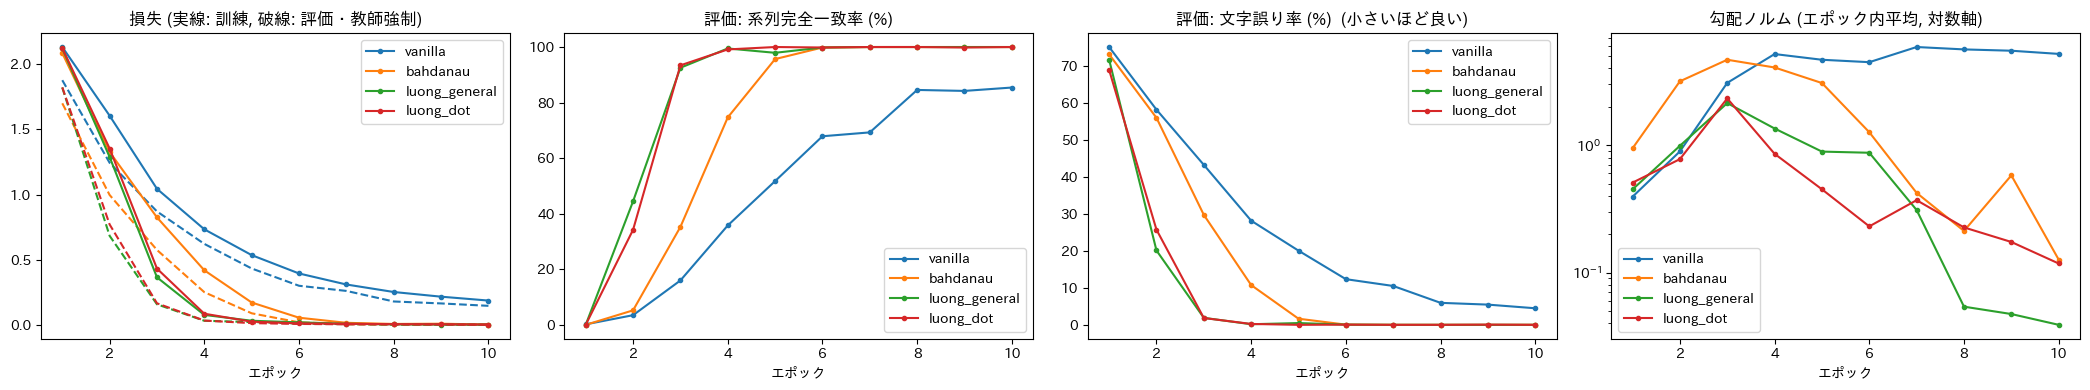

設定                評価損失      数字単位正解率      系列完全一致率      文字誤り率    EOS位置      勾配ノルム     クリップ   (最終エポック)
vanilla          0.148        95.1%        85.4%       4.5%    96.9%      5.207     100%
bahdanau         0.002       100.0%       100.0%       0.0%   100.0%      0.126       0%
luong_general    0.002       100.0%       100.0%       0.0%   100.0%      0.039       0%
luong_dot        0.003       100.0%       100.0%       0.0%   100.0%      0.118       0%

桁数ごとの系列完全一致率 (%)  (最終エポック)
設定                 4桁     5桁     6桁     7桁     8桁     9桁
vanilla         100.0  100.0   92.7   91.7   76.0   52.1
bahdanau        100.0  100.0  100.0  100.0  100.0  100.0
luong_general   100.0  100.0  100.0  100.0  100.0  100.0
luong_dot       100.0  100.0  100.0  100.0  100.0  100.0


In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(21, 4))
for name, (model, history, eval_ds) in runs.items():
    ep = [h['epoch'] for h in history]
    line, = axes[0].plot(ep, [h['train_loss'] for h in history], marker='o', ms=3, label=name)
    axes[0].plot(ep, [h['loss'] for h in history], ls='--', color=line.get_color())   # 評価損失(教師強制)
    axes[1].plot(ep, [h['seq_acc'] for h in history], marker='o', ms=3, label=name)
    axes[2].plot(ep, [h['cer'] for h in history], marker='o', ms=3, label=name)
    axes[3].plot(ep, [h['grad_norm_mean'] for h in history], marker='o', ms=3, label=name)
axes[0].set_title('損失 (実線: 訓練, 破線: 評価・教師強制)'); axes[1].set_title('評価: 系列完全一致率 (%)'); axes[2].set_title('評価: 文字誤り率 (%)  (小さいほど良い)')
axes[3].set_title('勾配ノルム (エポック内平均, 対数軸)'); axes[3].set_yscale('log')
for ax in axes:
    ax.set_xlabel('エポック'); ax.legend()
plt.tight_layout(); plt.show()

print(f"{'設定':14s} {'評価損失':>7s} {'数字単位正解率':>12s} {'系列完全一致率':>12s} {'文字誤り率':>10s} {'EOS位置':>8s} {'勾配ノルム':>10s} {'クリップ':>8s}   (最終エポック)")
for name, (model, history, eval_ds) in runs.items():
    h = history[-1]
    print(f"{name:14s} {h['loss']:7.3f} {h['tok_acc']:11.1f}% {h['seq_acc']:11.1f}% {h['cer']:9.1f}% {h['len_acc']:7.1f}% {h['grad_norm_mean']:10.3f} {100 * h['clip_frac']:7.0f}%")

print('\n桁数ごとの系列完全一致率 (%)  (最終エポック)')
lens = sorted(runs[next(iter(runs))][1][-1]['seq_acc_by_len'])
print(f"{'設定':14s} " + ' '.join(f'{n:>5d}桁' for n in lens))
for name, (model, history, eval_ds) in runs.items():
    b = history[-1]['seq_acc_by_len']
    print(f"{name:14s} " + ' '.join(f'{b[n]:6.1f}' for n in lens))


# 系列位置曲線(順序効果)

心理学の系列再生の実験では、リストの**どの位置の項目**が正しく再生されたかを、位置ごとに描く(**系列位置曲線**)。
即時系列再生では、先頭付近(初頭効果)と末尾付近(新近性効果)の成績が高く、中ほどが低い「弓形」になることが多い。

ここでは、評価データ(長さ n)の各数字を、**入力の位置**ごとに「正しく出力できた割合」として描く。
2 種類の曲線を描く。

- **自由生成**(左): 評価の本番と同じ。前の時刻の誤りが後ろの時刻に伝わる。
- **教師強制**(右): 各時刻で正解を入力して、次の 1 桁だけを予測する。誤りの伝播がない。

**読み方の注意**: 自由生成の曲線は、誤りの伝播のせいで、出力の後ろの時刻ほど悪く見える。
逆唱では出力の後ろ = 入力の**前**の方、復唱では出力の後ろ = 入力の**後ろ**の方である。
人間の初頭効果・新近性効果のように見える形が、この伝播だけで作られることがある。
個々の位置の難しさは、教師強制の曲線で読むこと。
どのような形になるかは予想せず、結果で確かめること。


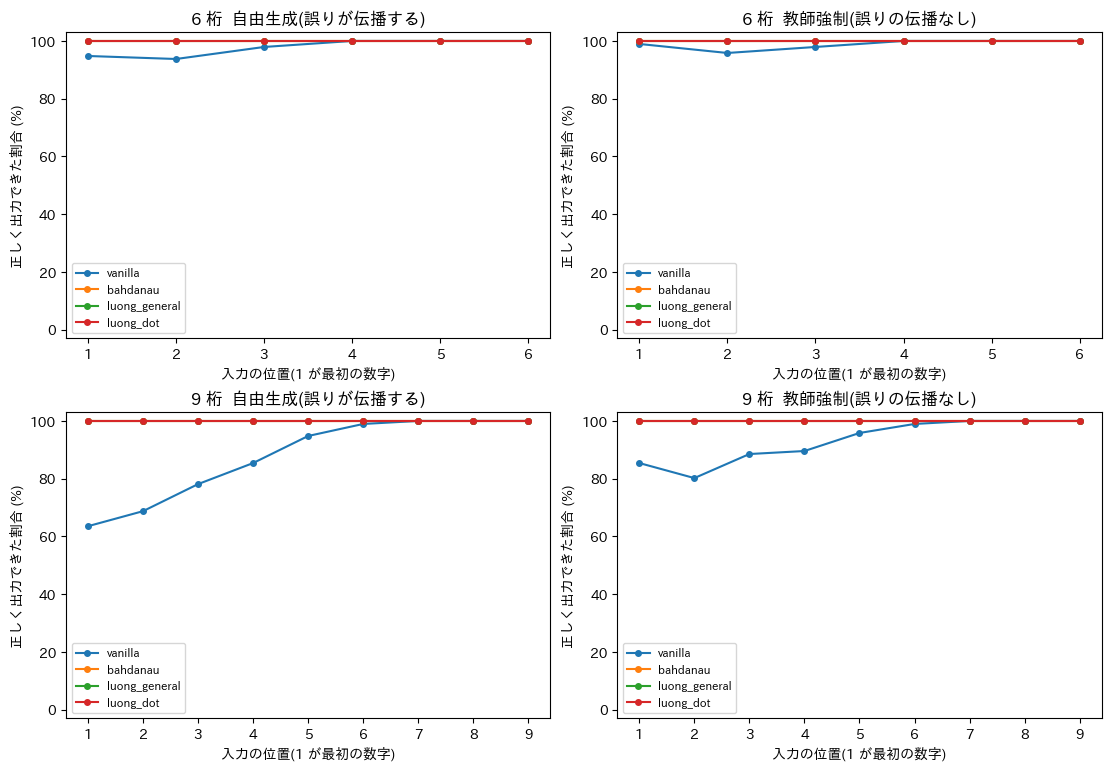

9 桁・教師強制: 入力の位置ごとの正解率 (%)
設定                 1     2     3     4     5     6     7     8     9
vanilla         85.4  80.2  88.5  89.6  95.8  99.0 100.0 100.0 100.0
bahdanau       100.0 100.0 100.0 100.0 100.0 100.0 100.0 100.0 100.0
luong_general  100.0 100.0 100.0 100.0 100.0 100.0 100.0 100.0 100.0
luong_dot      100.0 100.0 100.0 100.0 100.0 100.0 100.0 100.0 100.0


In [22]:
PLOT_LENGTHS = (6, 9)     # 描く桁数
POS = {}                  # POS[name][mode][n] = 入力の位置ごとの正解率
for name, (model, history, eval_ds) in runs.items():
    POS[name] = {mode: position_accuracy(model, eval_ds, teacher_forcing=(mode == 'teacher_forcing'))
                 for mode in ('free', 'teacher_forcing')}

fig, axes = plt.subplots(len(PLOT_LENGTHS), 2, figsize=(11, 3.8 * len(PLOT_LENGTHS)), squeeze=False, constrained_layout=True)
for r, n in enumerate(PLOT_LENGTHS):
    for c, (mode, title) in enumerate((('free', '自由生成(誤りが伝播する)'), ('teacher_forcing', '教師強制(誤りの伝播なし)'))):
        ax = axes[r][c]
        for name in runs:
            ax.plot(range(1, n + 1), 100 * POS[name][mode][n], marker='o', ms=4, label=name)
        ax.set_title(f'{n} 桁  {title}'); ax.set_xlabel('入力の位置(1 が最初の数字)'); ax.set_ylabel('正しく出力できた割合 (%)')
        ax.set_xticks(range(1, n + 1)); ax.set_ylim(-3, 103); ax.legend(loc='lower left', fontsize=8)
plt.show()

n = max(PLOT_LENGTHS)
print(f'{n} 桁・教師強制: 入力の位置ごとの正解率 (%)')
print(f"{'設定':14s} " + ' '.join(f'{i:>5d}' for i in range(1, n + 1)))
for name in runs:
    print(f"{name:14s} " + ' '.join(f'{100 * v:5.1f}' for v in POS[name]['teacher_forcing'][n]))


# 勾配ノルムの確認

勾配が小さくなりすぎる(勾配消失)と、学習が進まない。再帰型ネットワークでは、
出力の誤差が**遠い過去の入力まで**伝わる間に勾配が小さくなりやすい。特に SRN で顕著とされる。
学習が進まないとき、それが「実装の誤り」なのか「勾配消失」なのかを見分けるために、次の 2 つを確かめる。

1. 上の図の右端: エポックごとの勾配ノルム(全パラメータをまとめた L2 ノルム。**クリップ前**の値)。ほぼ 0 なら勾配消失、
   非常に大きい / `nan` なら勾配爆発や学習の破綻を疑う。
2. 下の図: 学習後のモデルで、損失の入力 one-hot に関する勾配のノルムを、**入力の位置ごと**に描く。
   遠い位置ほど勾配が小さければ、勾配が時間をさかのぼる間に減衰している。注意なし(vanilla)では、
   符号化器の最終状態を通ってしか勾配が届かないため、減衰が大きいと予想される。
   注意付きでは、注意の重みを通して各位置に直接勾配が届くので、減衰は小さいと予想される(いずれも予想であり、結果で確かめること)。

訓練時と同じ条件(教師強制あり)で計算する。層間 dropout が有効な場合は、値に多少のばらつきが入る。


vanilla        位置1: 1.30e-02  位置9: 1.19e-01  最大/最小: 9.1 倍
bahdanau       位置1: 4.04e-04  位置9: 9.32e-04  最大/最小: 2.7 倍
luong_general  位置1: 1.21e-04  位置9: 1.33e-04  最大/最小: 1.6 倍
luong_dot      位置1: 3.11e-04  位置9: 8.71e-04  最大/最小: 2.9 倍


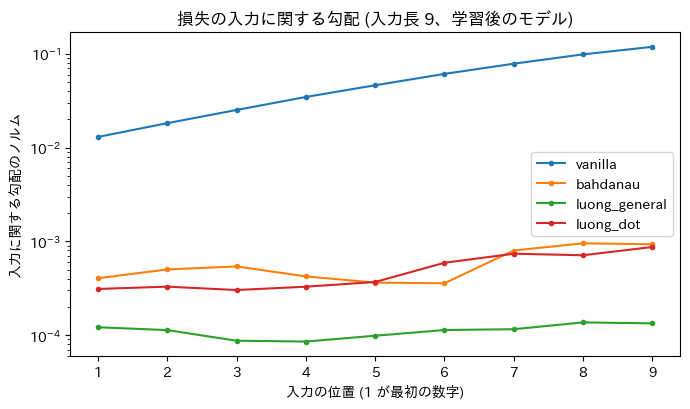

In [23]:
def input_gradient_profile(model, dataset, length=9, n=32):
    """長さ length の評価データ n 件について、損失の入力 one-hot に関する勾配のノルムを、入力の位置ごとに平均する。"""
    idx = [k for k, s in enumerate(dataset.strings) if len(s) == length][:n]
    if not idx:
        raise ValueError(f'長さ {length} の評価データがない')
    x, y, x_len, y_len = pad_collate([dataset[k] for k in idx])      # 全て同じ長さなのでパディングなし
    device = next(model.parameters()).device
    x = x.to(device).float().requires_grad_(True)
    was_training = model.training
    model.train()
    enc_out, enc_state = model.encode(x, x_len)
    logits, labels, _ = model.decode(enc_out, enc_state, y.to(device).long(), y_len, x_len)
    loss = model.loss_fn(logits, labels)
    model.zero_grad()
    loss.backward()
    model.train(was_training)
    return x.grad.norm(dim=-1).mean(0).cpu().numpy()                 # (length,)


PROFILE_LENGTH = 9
fig, ax = plt.subplots(figsize=(7, 4.2))
for name, (model, history, eval_ds) in runs.items():
    g = input_gradient_profile(model, eval_ds, PROFILE_LENGTH)
    ax.plot(range(1, PROFILE_LENGTH + 1), g, marker='o', ms=3, label=name)
    print(f"{name:14s} 位置1: {g[0]:.2e}  位置{PROFILE_LENGTH}: {g[-1]:.2e}  最大/最小: {g.max() / max(g.min(), 1e-30):.1f} 倍")
ax.set_yscale('log'); ax.set_xlabel('入力の位置 (1 が最初の数字)'); ax.set_ylabel('入力に関する勾配のノルム')
ax.set_title(f'損失の入力に関する勾配 (入力長 {PROFILE_LENGTH}、学習後のモデル)'); ax.legend()
plt.tight_layout(); plt.show()


# 注意の重み(アライメント)を見る

注意の重みを、縦軸を出力の時刻(上から下へ進む)、横軸を入力の位置として描く。

- **逆唱**(`reversed=True`): 出力の $t$ 番目は入力の「後ろから $t$ 番目」に対応するので、**右上から左下へ向かう線**(反対角線)になれば、反転に対応した注意である。
- **復唱**(`reversed=False`): 出力の $t$ 番目は入力の $t$ 番目に対応するので、**左上から右下へ向かう線**(対角線)になれば、対応がついている。

- 図 1: 長さの異なる評価データ 3 件について、1 件ずつ描く。軸の目盛りは実際の数字。
  縦軸の「正解/予測」が食い違った出力文字は赤で示す。
- 図 2: 評価データ全体について、**同じ入力長の系列の注意の重みを平均**して描く。個々の例によらず、
  どの位置に注目する傾向があるかが見える。破線は「対応する文字そのものの位置」を結んだ線。
- 注意なしの vanilla は注意の重みを持たないので描かない。

読むときの注意: 符号化器が**一方向**の再帰層のとき、入力の位置 $s$ の隠れ状態には、位置 $s$ 以前の文字の情報が
含まれる。そのため、モデルが「対応する文字そのものの位置」ではなく「その 1 つ後ろの位置」に注目しても、
正しく出力できることがある。破線から 1 つずれた線になっていても、誤りとは限らない(下の分布で確認できる)。
文字課題(a〜d、長さ 5〜14、GRU・1 層・単方向・逆唱。旧版)では、実際にほとんどが +1 のずれだった。この数字課題で同じになるかは、下の分布で確認すること。符号化器を双方向にすると、このずれがどう変わるかを調べられる
(変わると予想されるが、予想であり、結果で確かめること)。


In [24]:
def collect_alignments(model, dataset):
    """評価データ全件について、注意の重み行列 A[t, s] (出力の時刻 t x 入力の位置 s) を集める。
    正解の長さ(EOS を含む)までの出力を使う。自由生成では、時刻 t の出力は t-1 までの自分の出力にしか依存しないので、
    EOS 停止の評価で生成される最初の「正解長」ぶんの時刻と同じ値になる。"""
    chars = dataset.characters
    loader = data.DataLoader(dataset, batch_size=model.batch_size, shuffle=False,
                             collate_fn=pad_collate, drop_last=False)
    out = []
    model.eval()
    with torch.no_grad():
        for batch in loader:
            xs, ys, xl, yl = batch
            _, logits, labels, align = model.loss(batch)        # align: (出力長, 入力長, バッチ)
            align = align.detach().cpu().numpy()
            B = xs.size(0)
            pred = logits.argmax(-1).view(B, -1).cpu().numpy()
            for i in range(B):
                s, t = int(xl[i]), int(yl[i])
                to_ch = lambda k: '</s>' if k == 2 else (chars[k - 3] if 3 <= k < 3 + len(chars) else '?')
                out.append(dict(
                    src=[chars[k] for k in xs[i, :s].argmax(-1).tolist()],
                    true=[to_ch(int(k)) for k in ys[i, :t]],
                    pred=[to_ch(int(k)) for k in pred[i, :t]],
                    A=align[:t, :s, i]))
    return out


attn_runs = {k: v for k, v in runs.items() if v[0].use_attention}
collected = {k: collect_alignments(v[0], v[2]) for k, v in attn_runs.items()}

# 最大の注意位置が、理想位置(逆唱: 入力の後ろから t 番目 / 復唱: 入力の t 番目)からどれだけずれているかの分布
REVERSE = list(runs.values())[0][2].reverse
from collections import Counter
print(f"課題: {'逆唱' if REVERSE else '復唱'}")
print('最大の注意位置 - 理想位置 の分布 (0: 対応する文字そのもの, +1: その 1 つ後ろ)')
for name, items in collected.items():
    cnt = Counter()
    for it in items:
        L = len(it['src'])
        for t in range(L):
            ideal = (L - 1 - t) if REVERSE else t
            cnt[int(it['A'][t].argmax()) - ideal] += 1
    n = sum(cnt.values())
    print(f"  {name:14s}  0: {100 * cnt[0] / n:5.1f}%   +1: {100 * cnt[1] / n:5.1f}%   その他: {100 * (n - cnt[0] - cnt[1]) / n:5.1f}%")


課題: 逆唱
最大の注意位置 - 理想位置 の分布 (0: 対応する文字そのもの, +1: その 1 つ後ろ)
  bahdanau        0:  70.9%   +1:  29.1%   その他:   0.0%
  luong_general   0: 100.0%   +1:   0.0%   その他:   0.0%
  luong_dot       0: 100.0%   +1:   0.0%   その他:   0.0%


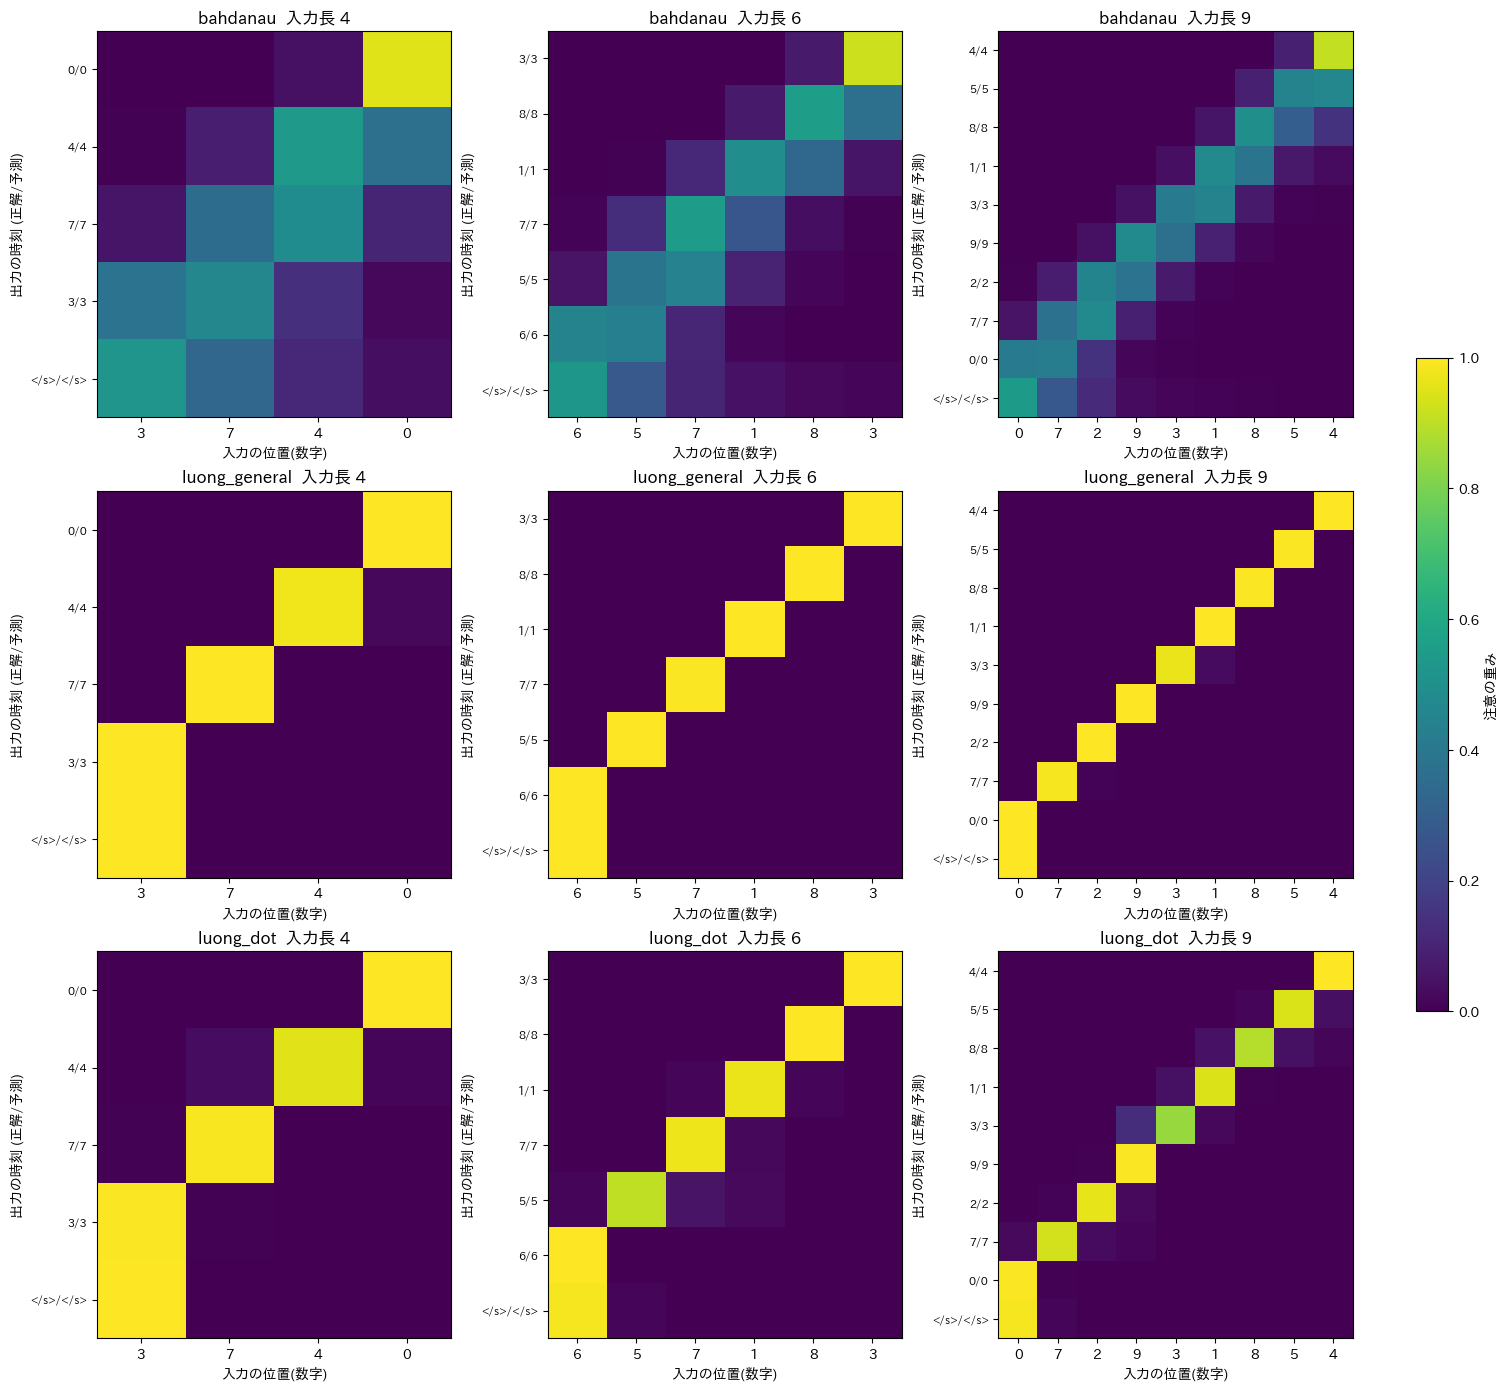

In [25]:
# 図 1: 長さ 4, 6, 9 の評価データを 1 件ずつ
LENGTHS = (4, 6, 9)
names = list(collected.keys())
fig, axes = plt.subplots(len(names), len(LENGTHS), figsize=(5.0 * len(LENGTHS), 4.6 * len(names)), squeeze=False, constrained_layout=True)
for r, name in enumerate(names):
    for c, L in enumerate(LENGTHS):
        it = next(x for x in collected[name] if len(x['src']) == L)
        ax = axes[r][c]
        im = ax.imshow(it['A'], cmap='viridis', vmin=0, vmax=1, aspect='auto')   # 上から下へ時刻が進む
        ax.set_xticks(range(L)); ax.set_xticklabels(it['src'])
        ax.set_yticks(range(len(it['true'])))
        ax.set_yticklabels([f"{t}/{p}" for t, p in zip(it['true'], it['pred'])], fontsize=8)
        for lbl, t, p in zip(ax.get_yticklabels(), it['true'], it['pred']):
            lbl.set_color('black' if t == p else 'red')
        ax.set_xlabel('入力の位置(数字)'); ax.set_ylabel('出力の時刻 (正解/予測)')
        ax.set_title(f'{name}  入力長 {L}')
fig.colorbar(im, ax=axes, shrink=0.5, label='注意の重み')
plt.show()


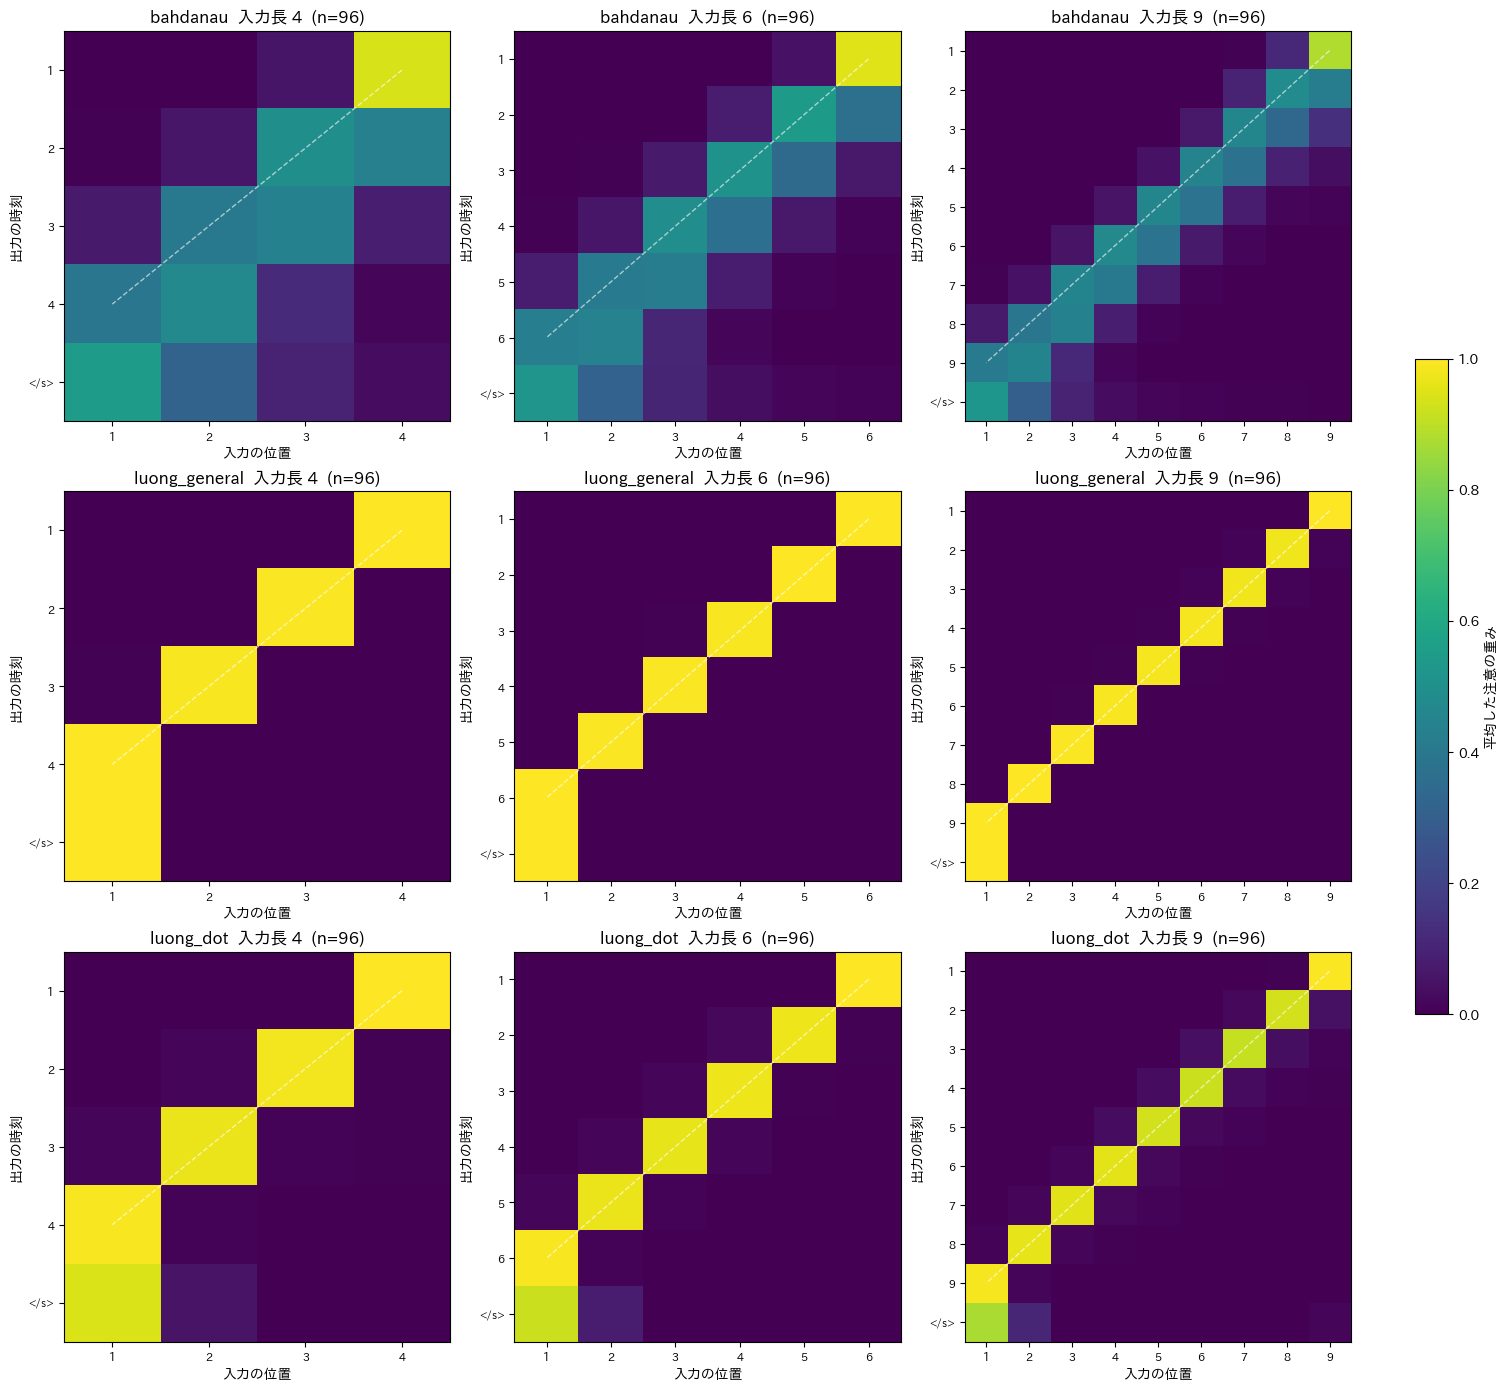

In [26]:
# 図 2: 同じ入力長の評価データ全件の平均
fig, axes = plt.subplots(len(names), len(LENGTHS), figsize=(5.0 * len(LENGTHS), 4.6 * len(names)), squeeze=False, constrained_layout=True)
for r, name in enumerate(names):
    for c, L in enumerate(LENGTHS):
        group = [x['A'] for x in collected[name] if len(x['src']) == L]
        mean_A = np.mean(group, axis=0)
        ax = axes[r][c]
        im = ax.imshow(mean_A, cmap='viridis', vmin=0, vmax=1, aspect='auto')
        ax.plot(range(L - 1, -1, -1) if REVERSE else range(L), range(L), 'w--', lw=1, alpha=0.6)   # 対応する文字そのものの位置
        ax.set_xticks(range(L)); ax.set_xticklabels(range(1, L + 1), fontsize=8)
        ax.set_yticks(range(L + 1)); ax.set_yticklabels(list(range(1, L + 1)) + ['</s>'], fontsize=8)
        ax.set_xlabel('入力の位置'); ax.set_ylabel('出力の時刻')
        ax.set_title(f'{name}  入力長 {L}  (n={len(group)})')
fig.colorbar(im, ax=axes, shrink=0.5, label='平均した注意の重み')
plt.show()
